## Đọc dữ liệu và chọn hai biến

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Đọc dữ liệu
df = pd.read_csv("./data/penguins_lter.csv")

# Kiểm tra tên cột
print(df.columns.tolist())

['studyName', 'Sample Number', 'Species', 'Region', 'Island', 'Stage', 'Individual ID', 'Clutch Completion', 'Date Egg', 'Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)', 'Sex', 'Delta 15 N (o/oo)', 'Delta 13 C (o/oo)', 'Comments']


## Làm sạch dữ liệu

In [3]:
# Chỉ lấy hai biến cần phân tích
data = df[["Flipper Length (mm)", "Body Mass (g)"]].copy()

# Chuyển về kiểu số, giá trị không hợp lệ thành NaN
data = data.apply(pd.to_numeric, errors="coerce")

# Loại bỏ dòng bị thiếu dữ liệu
data = data.dropna()

print("Số dòng sau khi làm sạch:", len(data))
display(data.head())

Số dòng sau khi làm sạch: 342


,Flipper Length (mm),Body Mass (g)
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
4,193.0,3450.0
5,190.0,3650.0


## Vẽ biểu đồ phân tán (Scatter Plot)

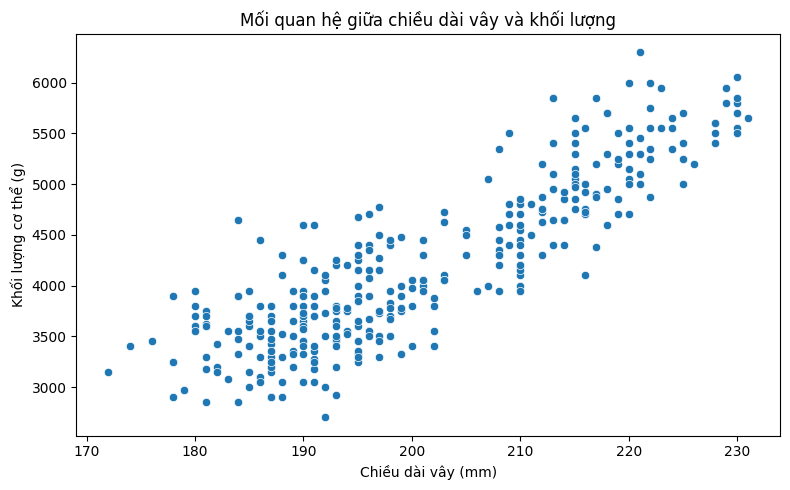

In [4]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Flipper Length (mm)",
    y="Body Mass (g)"
)

plt.title("Mối quan hệ giữa chiều dài vây và khối lượng")
plt.xlabel("Chiều dài vây (mm)")
plt.ylabel("Khối lượng cơ thể (g)")
plt.tight_layout()
plt.show()

## Tính hệ số tương quan

In [5]:
r = data["Flipper Length (mm)"].corr(
    data["Body Mass (g)"]
)

print("Hệ số tương quan Pearson:", round(r, 4))

Hệ số tương quan Pearson: 0.8712


## Xây dựng mô hình hồi quy tuyến tính bằng Scikit-learn

In [6]:
# X phải là bảng 2 chiều; y là chuỗi 1 chiều
X = data[["Flipper Length (mm)"]]
y = data["Body Mass (g)"]

# Chia dữ liệu: 80% huấn luyện, 20% kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Khởi tạo và huấn luyện mô hình
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

print("Hệ số góc:", model.coef_[0])
print("Hệ số chặn:", model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

Hệ số góc: 48.82968281899301
Hệ số chặn: -5614.067120606899
MAE: 315.85971744954526
R²: 0.7820354165340795


## Vẽ đường hồi quy

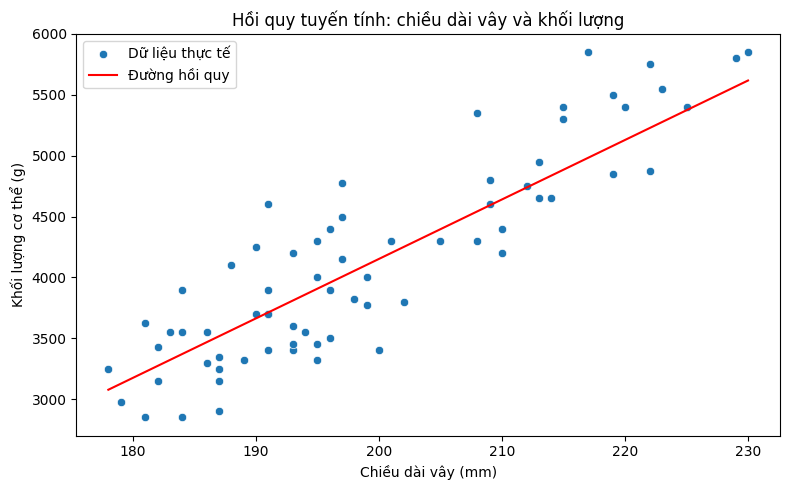

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_test["Flipper Length (mm)"],
    y=y_test,
    label="Dữ liệu thực tế"
)

# Sắp xếp X để đường dự đoán được vẽ liên tục
order = np.argsort(X_test["Flipper Length (mm)"].to_numpy())
x_sorted = X_test.iloc[order]
y_sorted = y_pred[order]

plt.plot(
    x_sorted["Flipper Length (mm)"],
    y_sorted,
    color="red",
    label="Đường hồi quy"
)

plt.title("Hồi quy tuyến tính: chiều dài vây và khối lượng")
plt.xlabel("Chiều dài vây (mm)")
plt.ylabel("Khối lượng cơ thể (g)")
plt.legend()
plt.tight_layout()
plt.show()